# Path-Based Structural Importance — Causal Discovery Ablation (λ = 0.75)

**Configurations:** Full, No_NOTEARS, No_GOLEM, No_DAGMA. Frozen models and thresholds are loaded from `frozen_models/` beside this notebook. **No model is retrained.**

**Primary comparison:** top-*k* **distinct action targets**, *k* = 1,…,6, with one highest-ranked recommendation per target. This prevents repeated actions on `PaymentMethod`, `Contract`, or `InternetService` from consuming the nominal budget without introducing a new intervention dimension.

**Secondary sensitivity analysis:** top-*k* ranked **action rows**, *k* = 1,…,9, with the existing first-change-per-target rule. The two budgets are not equivalent and are reported separately.

The output includes Jaccard overlap of recommended-action `Source` sets, Spearman rank correlation on shared `Source` features, and analogous target-set overlap. Results are model-predicted changes, **not observed treatment effects**.
**Budget definition:** all rows with a valid `Action_Target`, including `Actionable = NO`, are eligible for selection. Distinct-target and ranked-row budgets are both reported.


## 0. Setup and files

In [ ]:
import os, re, json, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, roc_auc_score, accuracy_score, precision_score, recall_score, f1_score
from IPython.display import display
warnings.filterwarnings("ignore", category=FutureWarning)

# Set to Path(r"C:/path/to/project") if your Jupyter kernel starts elsewhere.
PROJECT_DIR = Path.cwd().resolve()
MODEL_DIR = PROJECT_DIR / "frozen_models"
METADATA_FILE = MODEL_DIR / "experiment_metadata.json"
ACTIONS_FILE = PROJECT_DIR / "PathStructural_Ablation_Lambda075.xlsx"
TELCO_FILE = PROJECT_DIR / "Telco-Customer-Churn.xlsx"
OUTPUT_FILE = PROJECT_DIR / "PathStructural_Ablation_Lambda075_Results.xlsx"
FIGURE_DIR = PROJECT_DIR / "Ablation_Figures"
FIGURE_DIR.mkdir(exist_ok=True)

CONFIGS = ["Full", "No_NOTEARS", "No_GOLEM", "No_DAGMA"]
MODEL_ORDER = ["XGBoost", "RandomForest", "GBM", "CatBoost"]
MONTHLY_CHARGES_REDUCTION_PCT = 0.10
APPLY_CANDIDATE_ACTIONS = True
BOOTSTRAP_REPS = 10000
BOOTSTRAP_SEED = 20261118

for f in (METADATA_FILE, ACTIONS_FILE, TELCO_FILE):
    if not f.exists():
        raise FileNotFoundError(f"Missing required input: {f}. Set PROJECT_DIR or rename the input file.")
print("Project directory:", PROJECT_DIR)


## 1. Load frozen metadata, Telco data, and ablation rankings

In [2]:
with open(METADATA_FILE, encoding="utf-8") as f:
    metadata = json.load(f)
SEED = int(metadata["seed"])
thresholds = {k: float(v) for k,v in metadata["thresholds"].items()}
expected_models = metadata.get("models", MODEL_ORDER)
catboost_cat_cols = metadata.get("catboost_native_categoricals", [])
catboost_num_cols = metadata.get("catboost_numeric_columns", [])
catboost_numeric_medians = pd.Series(metadata.get("catboost_numeric_medians", {}), dtype=float)

xls = pd.ExcelFile(TELCO_FILE)
telco = pd.read_excel(TELCO_FILE, sheet_name="Dataset" if "Dataset" in xls.sheet_names else 0)
telco["TotalCharges"] = pd.to_numeric(telco["TotalCharges"], errors="coerce")

REQUIRED = {"Source", "Sign", "Actionable", "Action_Target", "Recommended_Action", "Global Rank", "Global Score"}
all_actions, eligible_actions, availability = {}, {}, []
for cfg in CONFIGS:
    df = pd.read_excel(ACTIONS_FILE, sheet_name=cfg)
    missing = REQUIRED - set(df.columns)
    if missing:
        raise ValueError(f"{cfg} missing columns: {sorted(missing)}")
    df["Source"] = df["Source"].astype(str).str.strip()
    df["Action_Target"] = df["Action_Target"].fillna("").astype(str).str.strip()
    df["Global Score"] = pd.to_numeric(df["Global Score"], errors="raise")
    df["Global Rank"] = pd.to_numeric(df["Global Rank"], errors="raise")
    df = df.sort_values(["Global Rank", "Global Score", "Source"], ascending=[True,False,True],kind="stable").reset_index(drop=True)
    df["Configuration"] = cfg
    all_actions[cfg] = df
    # Match 4.1: Actionable=NO does not exclude a row; Action_Target determines eligibility.
    valid = df.loc[df["Action_Target"].ne("") & df["Action_Target"].str.lower().ne("nan")].copy()
    if valid["Source"].duplicated().any():
        raise ValueError(f"Duplicate actionable Source in {cfg}")
    eligible_actions[cfg] = valid
    availability.append({"Configuration":cfg,"Recommended_Action_Rows":len(valid),"Distinct_Targets":valid["Action_Target"].nunique(),"Rows_Without_Action_Target":len(df)-len(valid),"Selected_Rows_Marked_NO":int(valid["Actionable"].astype(str).str.upper().eq("NO").sum())})
availability_df = pd.DataFrame(availability)
MAX_TARGET_K = int(availability_df["Distinct_Targets"].min())
MAX_ROW_K = int(availability_df["Recommended_Action_Rows"].min())
print("Common distinct-target budgets: 1..", MAX_TARGET_K)
print("Common ranked-row budgets: 1..", MAX_ROW_K)
display(availability_df)

bad_targets = set().union(*(set(x["Action_Target"]) for x in eligible_actions.values())) - set(telco.columns)
if bad_targets:
    raise ValueError(f"Action targets missing from Telco dataset: {sorted(bad_targets)}")


Common distinct-target budgets: 1.. 6
Common ranked-row budgets: 1.. 10


,Configuration,Recommended_Action_Rows,Distinct_Targets,Rows_Without_Action_Target,Selected_Rows_Marked_NO
0,Full,15,9,0,2
1,No_NOTEARS,10,8,0,0
2,No_GOLEM,12,6,0,2
3,No_DAGMA,11,8,0,2


## 2. Overlap of recommended-action features, targets, and rankings

In [3]:
def jaccard(a,b):
    a,b = set(a),set(b)
    return len(a&b)/len(a|b) if (a|b) else np.nan

def shared_rank_spearman(left,right):
    # Ranks are recomputed within the common Source subset to avoid missing-feature imputation.
    x=left.set_index("Source")["Global Rank"]
    y=right.set_index("Source")["Global Rank"]
    shared=sorted(set(x.index)&set(y.index))
    if len(shared)<2:
        return np.nan, len(shared)
    xv=x.loc[shared].rank(method="average").to_numpy(dtype=float)
    yv=y.loc[shared].rank(method="average").to_numpy(dtype=float)
    if np.std(xv)==0 or np.std(yv)==0:
        return np.nan, len(shared)
    return float(spearmanr(xv,yv).statistic),len(shared)

full=eligible_actions["Full"]
overlap_rows=[]
for cfg in CONFIGS[1:]:
    other=eligible_actions[cfg]
    rho,n_shared=shared_rank_spearman(full,other)
    src_full,src_other=set(full.Source),set(other.Source)
    tgt_full,tgt_other=set(full.Action_Target),set(other.Action_Target)
    overlap_rows.append({
        "Ablation":cfg,"Full_Source_N":len(src_full),"Ablated_Source_N":len(src_other),
        "Shared_Source_N":n_shared,"Source_Jaccard":jaccard(src_full,src_other),
        "Shared_Source_Spearman_Rho":rho,
        "Full_Target_N":len(tgt_full),"Ablated_Target_N":len(tgt_other),
        "Shared_Target_N":len(tgt_full&tgt_other),"Target_Jaccard":jaccard(tgt_full,tgt_other),
        "Lost_Sources":"; ".join(sorted(src_full-src_other)),
        "Added_Sources":"; ".join(sorted(src_other-src_full)),
        "Lost_Targets":"; ".join(sorted(tgt_full-tgt_other)),
    })
overlap_df=pd.DataFrame(overlap_rows)
display(overlap_df)


,Ablation,Full_Source_N,Ablated_Source_N,Shared_Source_N,Source_Jaccard,Shared_Source_Spearman_Rho,Full_Target_N,Ablated_Target_N,Shared_Target_N,Target_Jaccard,Lost_Sources,Added_Sources,Lost_Targets
0,No_NOTEARS,15,10,10,0.666667,0.963636,9,8,8,0.888889,Contract_One_year; InternetService_No; Multipl...,,TechSupport
1,No_GOLEM,15,12,12,0.800000,0.932630,9,6,6,0.666667,DeviceProtection_Yes; MultipleLines_Yes; Onlin...,,DeviceProtection; MultipleLines; OnlineBackup
2,No_DAGMA,15,11,11,0.733333,0.970390,9,8,8,0.888889,PaymentMethod_Bank_transfer; PaymentMethod_Cre...,,PaymentMethod


## 3. Reproduce frozen test split and baseline predictions

In [4]:
train_df, temp_df = train_test_split(telco,test_size=.30,stratify=telco["Churn"],random_state=SEED)
valid_df,test_df = train_test_split(temp_df,test_size=.50,stratify=temp_df["Churn"],random_state=SEED)
X_test=test_df.drop(columns=["Churn","CustomerID"]).copy()
y_test=test_df["Churn"].astype(str).str.lower().eq("yes").astype(int)
model_files=metadata.get("model_files",{m:f"{m}.joblib" for m in expected_models})
models={}
for m in expected_models:
    p=MODEL_DIR/model_files.get(m,f"{m}.joblib")
    if not p.exists():raise FileNotFoundError(f"Missing frozen model: {p}")
    models[m]=joblib.load(p)
if set(models)!=set(thresholds):raise ValueError("Model names and threshold keys do not match")

# The frozen preprocessing convention matches the original experiment notebook.
def transform_catboost_frozen(X):
    X_cb=X.copy()
    for col in catboost_num_cols:
        if col in X_cb:
            med=float(catboost_numeric_medians[col]) if col in catboost_numeric_medians.index else pd.to_numeric(X_cb[col],errors="coerce").median()
            X_cb[col]=pd.to_numeric(X_cb[col],errors="coerce").fillna(med).astype(float)
    for col in catboost_cat_cols:
        if col in X_cb:X_cb[col]=X_cb[col].fillna("__MISSING__").astype(str)
    return X_cb

def predict_proba_frozen(m,X):
    return models[m].predict_proba(transform_catboost_frozen(X) if m=="CatBoost" else X)[:,1]

baseline_probs={m:predict_proba_frozen(m,X_test) for m in expected_models}
baseline_pred={m:baseline_probs[m]>=thresholds[m] for m in expected_models}
actual_churn=y_test.to_numpy().astype(bool)
baseline_rows=[]
for m in expected_models:
    tn,fp,fn,tp=confusion_matrix(y_test,baseline_pred[m],labels=[0,1]).ravel()
    baseline_rows.append({"Model":m,"Threshold":thresholds[m],"TP":tp,"FP":fp,"FN":fn,"TN":tn,"Targeted_TP_plus_FP":tp+fp,"Targeted_Pct":100*(tp+fp)/len(test_df)})
baseline_df=pd.DataFrame(baseline_rows)
display(baseline_df)


,Model,Threshold,TP,FP,FN,TN,Targeted_TP_plus_FP,Targeted_Pct
0,XGBoost,0.380,185,122,96,654,307,29.044465
1,RandomForest,0.380,185,123,96,653,308,29.139073
2,GBM,0.365,191,127,90,649,318,30.085147
3,CatBoost,0.380,182,118,99,658,300,28.382214


## 4. Intervention parsing and logical consistency rules (same as the original experiment)
**Important:** `Actionable = NO` is not an exclusion criterion. A valid `Action_Target` triggers the recommended action, subject to the original source-state and dependency constraints.


In [5]:
CATEGORY_VALUES = {
    "PhoneService": ["No", "Yes"],
    "MultipleLines": ["No", "Yes", "No phone service"],
    "InternetService": ["DSL", "Fiber optic", "No"],
    "OnlineSecurity": ["No", "Yes", "No internet service"],
    "OnlineBackup": ["No", "Yes", "No internet service"],
    "DeviceProtection": ["No", "Yes", "No internet service"],
    "TechSupport": ["No", "Yes", "No internet service"],
    "StreamingTV": ["No", "Yes", "No internet service"],
    "StreamingMovies": ["No", "Yes", "No internet service"],
    "Contract": ["Month-to-month", "One year", "Two year"],
    "PaymentMethod": ["Electronic check", "Mailed check", "Bank transfer (automatic)", "Credit card (automatic)"],
}

def norm(value):
    return re.sub(r"[^a-z0-9]+", "", str(value).lower())

def decode_source_state(source, target):
    if target not in CATEGORY_VALUES:
        return None
    if norm(source) == norm(target) and "Yes" in CATEGORY_VALUES[target]:
        return "Yes"
    for value in CATEGORY_VALUES[target]:
        if norm(value) in norm(source):
            return value
    return None

def normalize_recommended_value(target, value):
    mapping = {
        ("PaymentMethod", "Credit card"): "Credit card (automatic)",
        ("PaymentMethod", "Bank transfer"): "Bank transfer (automatic)",
    }
    return mapping.get((target, value), value)

def parse_action(row):
    text = str(row["Recommended_Action"]).strip()
    target = str(row["Action_Target"]).strip()
    candidate = "(candidate)" in text.lower()
    if target == "MonthlyCharges" and text.lower().startswith("reduce"):
        return {"kind": "reduce", "target": target, "value": MONTHLY_CHARGES_REDUCTION_PCT, "candidate": candidate}
    match = re.search(r"=\s*(.+)$", text)
    if not match:
        raise ValueError(f"Cannot parse action for {row['Source']}: {text}")
    value = re.sub(r"\s*\(candidate\)\s*$", "", match.group(1).strip(), flags=re.I)
    return {"kind": "set", "target": target, "value": normalize_recommended_value(target, value), "candidate": candidate}

for strategy, actions in eligible_actions.items():
    actions = actions.copy()
    actions["_parsed"] = actions.apply(parse_action, axis=1)
    actions["_source_state"] = actions.apply(lambda r: decode_source_state(r["Source"], r["Action_Target"]), axis=1)
    actions["Is_Candidate_Action"] = actions["_parsed"].apply(lambda x: bool(x["candidate"]))
    eligible_actions[strategy] = actions


In [6]:
INTERNET_DEPENDENT = {
    "OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies"
}

def enforce_service_activation_dependencies(modified, target, value, changed_mask, previous_values):
    """Apply deterministic consistency adjustments after a primary service activation.

    InternetService: No -> DSL sets all six add-ons to No; Fiber optic -> DSL
    preserves their existing Yes/No values. PhoneService: No -> Yes sets
    MultipleLines to No. No other service transitions are handled here.
    """
    if target == "InternetService" and value == "DSL":
        activated = changed_mask & (previous_values == "No")
        for dependent in INTERNET_DEPENDENT:
            if dependent not in modified.columns:
                raise ValueError(f"Missing internet-dependent column: {dependent}")
            modified.loc[activated, dependent] = "No"
    elif target == "PhoneService" and value == "Yes":
        activated = changed_mask & (previous_values == "No")
        if "MultipleLines" not in modified.columns:
            raise ValueError("Missing phone-dependent column: MultipleLines")
        modified.loc[activated, "MultipleLines"] = "No"

def select_actions(configuration,k,budget_type):
    ranked=eligible_actions[configuration].sort_values(["Global Rank","Global Score","Source"],ascending=[True,False,True],kind="stable")
    if budget_type=="DistinctTargets":
        ranked=ranked.drop_duplicates("Action_Target",keep="first")
    elif budget_type!="RankedRows":
        raise ValueError(budget_type)
    return ranked.head(k).copy()

def apply_budget(df_original,baseline_positive_mask,selected):
    modified=df_original.copy(deep=True)
    applied_counts=np.zeros(len(modified),dtype=int)
    log=[]
    already_changed={t:np.zeros(len(modified),dtype=bool) for t in selected["Action_Target"].unique()}
    for _,row in selected.iterrows():
        rec=row["_parsed"]
        if rec["candidate"] and not APPLY_CANDIDATE_ACTIONS:continue
        target=rec["target"]
        mask=np.asarray(baseline_positive_mask,dtype=bool).copy()
        if row["Sign"]=="+" and row["_source_state"] is not None:
            mask &= modified[target].astype(str).to_numpy()==str(row["_source_state"])
        mask &= ~already_changed[target]
        if rec["kind"]=="set":
            mask &= modified[target].astype(str).to_numpy()!=str(rec["value"])
            if target in INTERNET_DEPENDENT and rec["value"]=="Yes":
                mask &= modified["InternetService"].astype(str).to_numpy()!="No"
            if target=="MultipleLines" and rec["value"]=="Yes":
                mask &= modified["PhoneService"].astype(str).to_numpy()=="Yes"
            previous=modified[target].astype(str).to_numpy().copy()
            modified.loc[mask,target]=rec["value"]
            enforce_service_activation_dependencies(modified,target,rec["value"],mask,previous)
        elif rec["kind"]=="reduce":
            modified.loc[mask,target]=modified.loc[mask,target].astype(float)*(1.0-rec["value"])
        else:raise ValueError(rec["kind"])
        already_changed[target]|=mask
        applied_counts+=mask.astype(int)
        log.append({"Source":row["Source"],"Target":target,"Recommended_Action":row["Recommended_Action"],"Changed_Customers":int(mask.sum())})
    return modified,applied_counts,pd.DataFrame(log)


## 5. Fixed-budget intervention simulations

The **baseline TP/FP cohorts remain fixed** for all configurations. Each selected recommendation is applied only where feasible and where the source-state condition holds. `Applied_Primary_Actions` counts actual primary changes; automatic dependent-feature adjustments are not counted as separate recommendations. The same frozen model evaluates each modified customer record.

In [7]:
cohort_rows=[];customer_frames=[];action_log_frames=[];selection_rows=[]
for budget_type,max_k in [("DistinctTargets",MAX_TARGET_K),("RankedRows",MAX_ROW_K)]:
    for k in range(1,max_k+1):
        for cfg in CONFIGS:
            selected=select_actions(cfg,k,budget_type)
            selection_rows.extend({"Budget_Type":budget_type,"k":k,"Configuration":cfg,"Selection_Order":i+1,"Source":r["Source"],"Action_Target":r["Action_Target"],"Global_Rank":r["Global Rank"],"Global_Score":r["Global Score"]} for i,(_,r) in enumerate(selected.iterrows()))
            for m in expected_models:
                before=baseline_probs[m];mask_pos=baseline_pred[m];thr=thresholds[m]
                changed,applied,log=apply_budget(test_df,mask_pos,selected)
                after=predict_proba_frozen(m,changed.drop(columns=["Churn","CustomerID"]))
                delta=before-after
                masks={"TP":mask_pos & actual_churn,"FP":mask_pos & ~actual_churn,"TP+FP":mask_pos}
                for cohort,mask in masks.items():
                    idx=np.where(mask)[0];d=delta[idx];a=applied[idx]
                    crossed=after[idx]<thr
                    cohort_rows.append({"Budget_Type":budget_type,"k":k,"Configuration":cfg,"Model":m,"Cohort":cohort,"N":len(idx),"Threshold":thr,"Mean_Delta_P":float(d.mean()) if len(d) else np.nan,"Median_Delta_P":float(np.median(d)) if len(d) else np.nan,"Threshold_Crossed_N":int(crossed.sum()),"Threshold_Crossing_Rate":float(crossed.mean()) if len(d) else np.nan,"Worsened_N":int((d < -1e-12).sum()),"Mean_Applied_Primary_Actions":float(a.mean()) if len(a) else np.nan,"Pct_With_Any_Applied_Action":float((a>0).mean()) if len(a) else np.nan,"Selected_Action_Rows":len(selected),"Selected_Distinct_Targets":selected["Action_Target"].nunique()})
                idx=np.where(mask_pos)[0]
                customer_frames.append(pd.DataFrame({"CustomerID":test_df["CustomerID"].to_numpy()[idx],"Budget_Type":budget_type,"k":k,"Configuration":cfg,"Model":m,"Cohort":np.where(actual_churn[idx],"TP","FP"),"P_Before":before[idx],"P_After":after[idx],"Delta_P":delta[idx],"Threshold_Crossed":after[idx]<thr,"Applied_Primary_Actions":applied[idx]}))
                if not log.empty:
                    log=log.assign(Budget_Type=budget_type,k=k,Configuration=cfg,Model=m)
                    action_log_frames.append(log)
cohort_df=pd.DataFrame(cohort_rows)
customer_df=pd.concat(customer_frames,ignore_index=True)
selected_df=pd.DataFrame(selection_rows)
action_log_df=pd.concat(action_log_frames,ignore_index=True) if action_log_frames else pd.DataFrame()
display(cohort_df.query('Budget_Type=="DistinctTargets" and Cohort=="TP" and k==@MAX_TARGET_K'))


,Budget_Type,k,Configuration,Model,Cohort,N,Threshold,Mean_Delta_P,Median_Delta_P,Threshold_Crossed_N,Threshold_Crossing_Rate,Worsened_N,Mean_Applied_Primary_Actions,Pct_With_Any_Applied_Action,Selected_Action_Rows,Selected_Distinct_Targets
240,DistinctTargets,6,Full,XGBoost,TP,185,0.380,0.399623,0.401372,175,0.945946,0,3.540541,1.0,6,6
243,DistinctTargets,6,Full,RandomForest,TP,185,0.380,0.373622,0.376177,183,0.989189,0,3.535135,1.0,6,6
246,DistinctTargets,6,Full,GBM,TP,191,0.365,0.406978,0.425981,173,0.905759,0,3.534031,1.0,6,6
249,DistinctTargets,6,Full,CatBoost,TP,182,0.380,0.438086,0.446133,174,0.956044,0,3.560440,1.0,6,6
252,DistinctTargets,6,No_NOTEARS,XGBoost,TP,185,0.380,0.396086,0.398442,174,0.940541,0,3.800000,1.0,6,6
255,DistinctTargets,6,No_NOTEARS,RandomForest,TP,185,0.380,0.366961,0.365182,181,0.978378,0,3.794595,1.0,6,6
258,DistinctTargets,6,No_NOTEARS,GBM,TP,191,0.365,0.398980,0.412462,171,0.895288,0,3.780105,1.0,6,6
261,DistinctTargets,6,No_NOTEARS,CatBoost,TP,182,0.380,0.432973,0.437612,173,0.950549,0,3.829670,1.0,6,6
264,DistinctTargets,6,No_GOLEM,XGBoost,TP,185,0.380,0.423686,0.422086,180,0.972973,0,3.627027,1.0,6,6
267,DistinctTargets,6,No_GOLEM,RandomForest,TP,185,0.380,0.402859,0.394548,185,1.000000,0,3.643243,1.0,6,6


## 6. Paired bootstrap 95% CIs: Full minus each ablation

Resampling is performed **by customer**, retaining the paired Full/ablated predicted risk reductions. Positive values favor the Full configuration. CIs are percentile bootstrap intervals (10,000 resamples). Cohorts are defined from the unchanged baseline predictions.

In [8]:
rng=np.random.default_rng(BOOTSTRAP_SEED)
paired_rows=[]
for (budget_type,k,m,cohort),grp in customer_df.groupby(["Budget_Type","k","Model","Cohort"],sort=False):
    wide=grp.pivot(index="CustomerID",columns="Configuration",values="Delta_P")
    for cfg in CONFIGS[1:]:
        pair=wide[["Full",cfg]].dropna()
        diff=(pair["Full"]-pair[cfg]).to_numpy(dtype=float)
        if len(diff)==0:continue
        boot=np.empty(BOOTSTRAP_REPS,dtype=float)
        for b in range(BOOTSTRAP_REPS):
            boot[b]=diff[rng.integers(0,len(diff),size=len(diff))].mean()
        lo,hi=np.quantile(boot,[.025,.975])
        paired_rows.append({"Budget_Type":budget_type,"k":k,"Model":m,"Cohort":cohort,"Ablation":cfg,"Paired_N":len(diff),"Mean_Difference_Full_minus_Ablated":float(diff.mean()),"Bootstrap_CI_Lower":float(lo),"Bootstrap_CI_Upper":float(hi),"CI_Excludes_Zero":bool(lo>0 or hi<0)})
paired_df=pd.DataFrame(paired_rows)
display(paired_df.query('Budget_Type=="DistinctTargets" and Cohort=="TP" and k==@MAX_TARGET_K'))


,Budget_Type,k,Model,Cohort,Ablation,Paired_N,Mean_Difference_Full_minus_Ablated,Bootstrap_CI_Lower,Bootstrap_CI_Upper,CI_Excludes_Zero
120,DistinctTargets,6,XGBoost,TP,No_NOTEARS,185,0.003536,0.001773,0.005634,True
121,DistinctTargets,6,XGBoost,TP,No_GOLEM,185,-0.024063,-0.027101,-0.020997,True
122,DistinctTargets,6,XGBoost,TP,No_DAGMA,185,0.035342,0.032164,0.038488,True
126,DistinctTargets,6,RandomForest,TP,No_NOTEARS,185,0.006661,0.005197,0.008206,True
127,DistinctTargets,6,RandomForest,TP,No_GOLEM,185,-0.029237,-0.033387,-0.025107,True
128,DistinctTargets,6,RandomForest,TP,No_DAGMA,185,0.014872,0.012243,0.017519,True
132,DistinctTargets,6,GBM,TP,No_NOTEARS,191,0.007999,0.005313,0.011038,True
133,DistinctTargets,6,GBM,TP,No_GOLEM,191,-0.020775,-0.023401,-0.018021,True
134,DistinctTargets,6,GBM,TP,No_DAGMA,191,0.064305,0.058212,0.070510,True
138,DistinctTargets,6,CatBoost,TP,No_NOTEARS,182,0.005113,0.002984,0.007809,True


## 7. Sensitivity figures

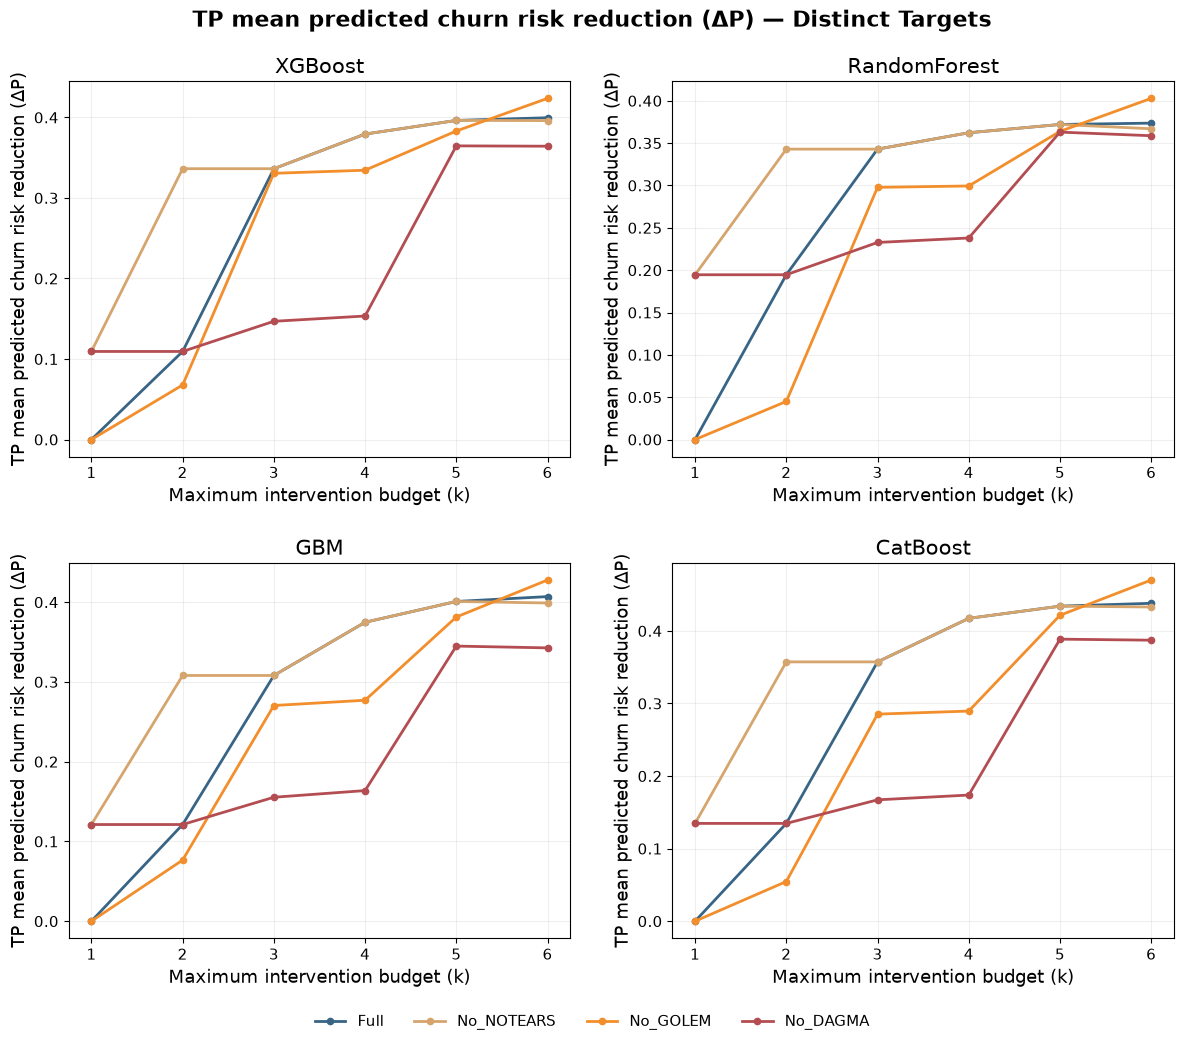

Saved Ablation_DistinctTargets_TP_Mean_Delta_P_600dpi.png


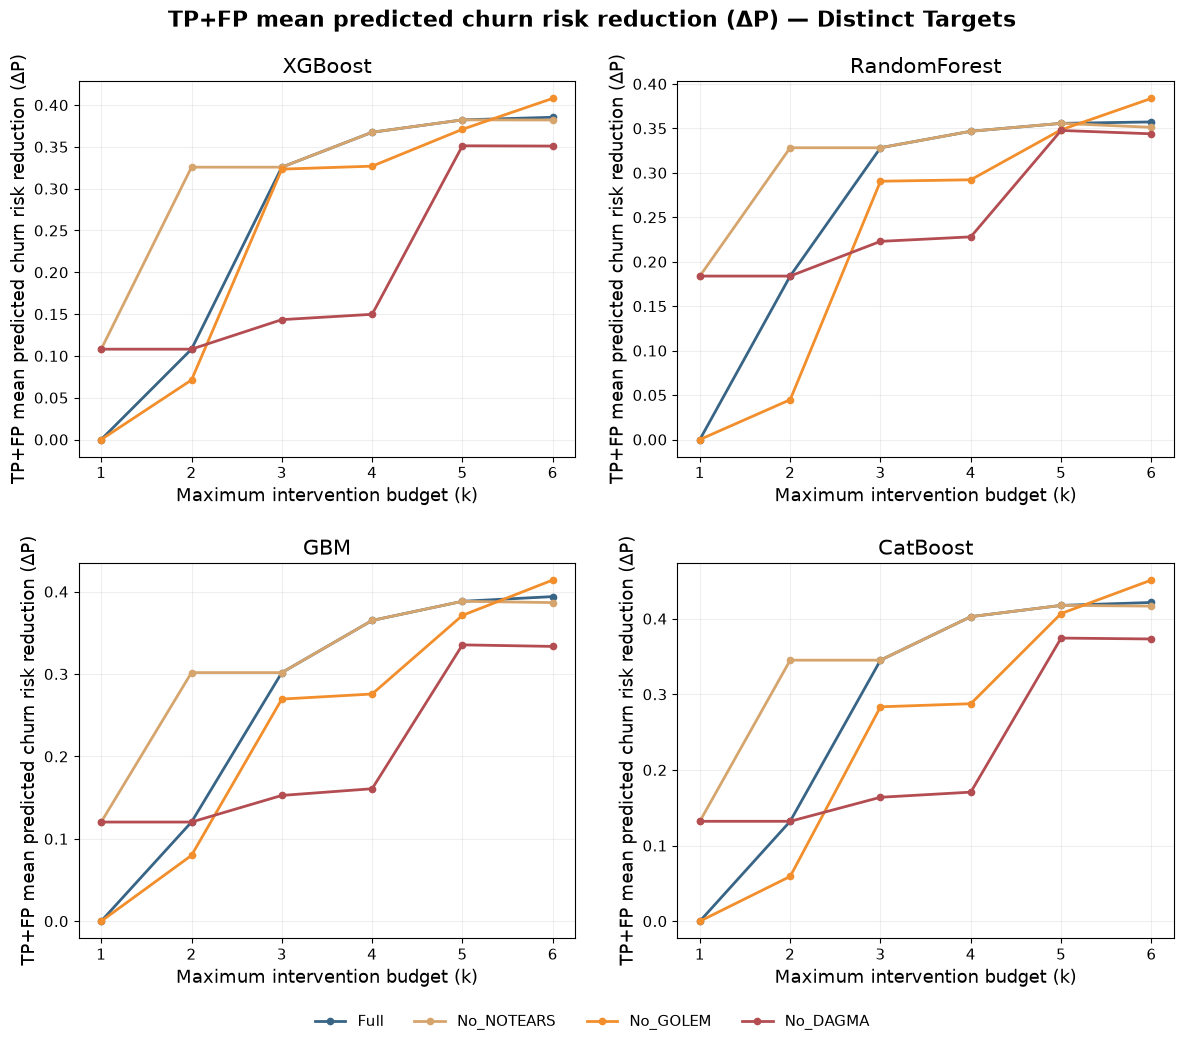

Saved Ablation_DistinctTargets_Targeted_Mean_Delta_P_600dpi.png


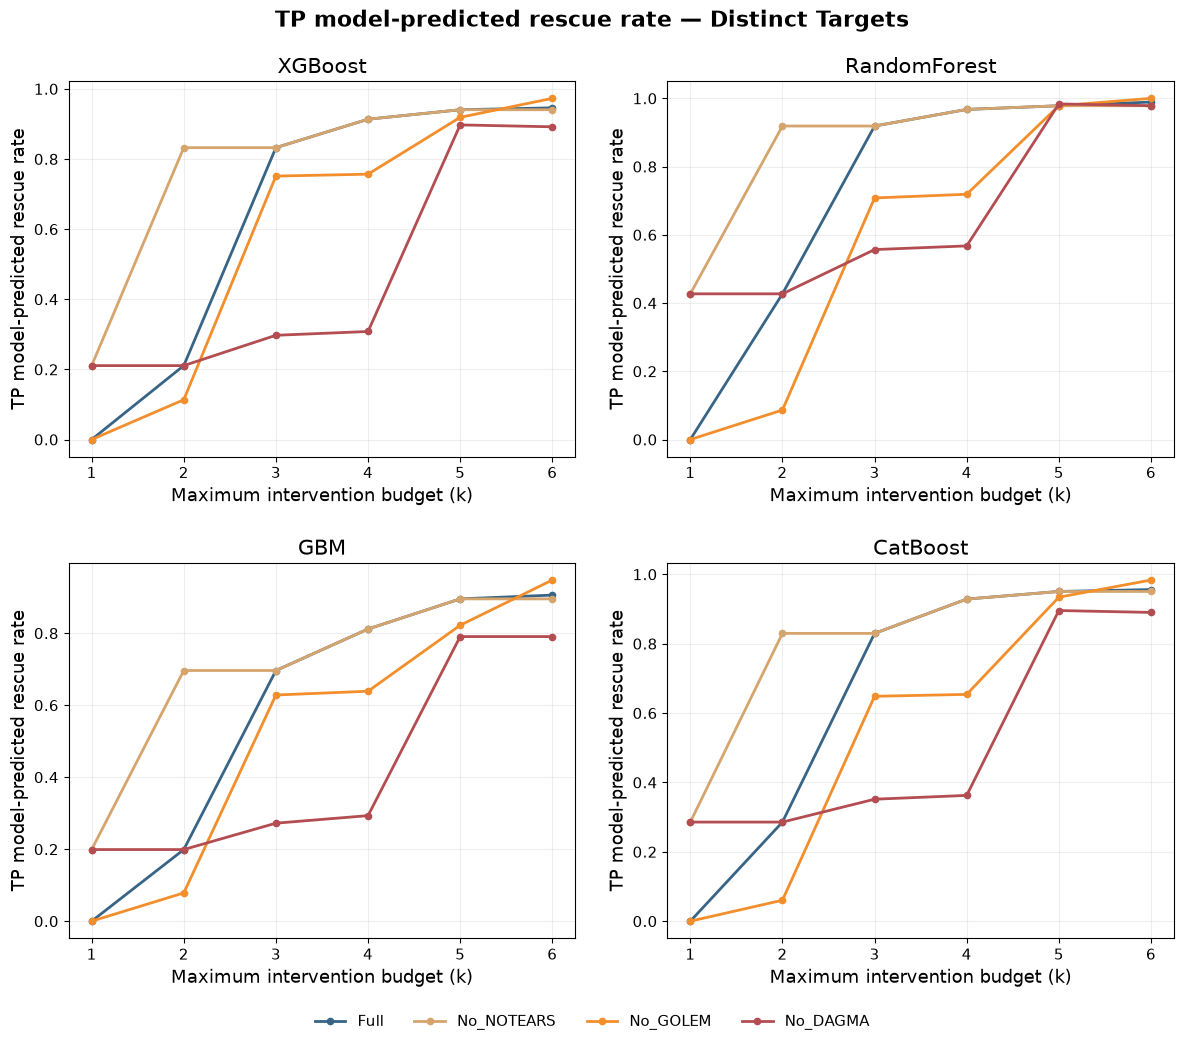

Saved Ablation_DistinctTargets_TP_Rescue_Rate_600dpi.png


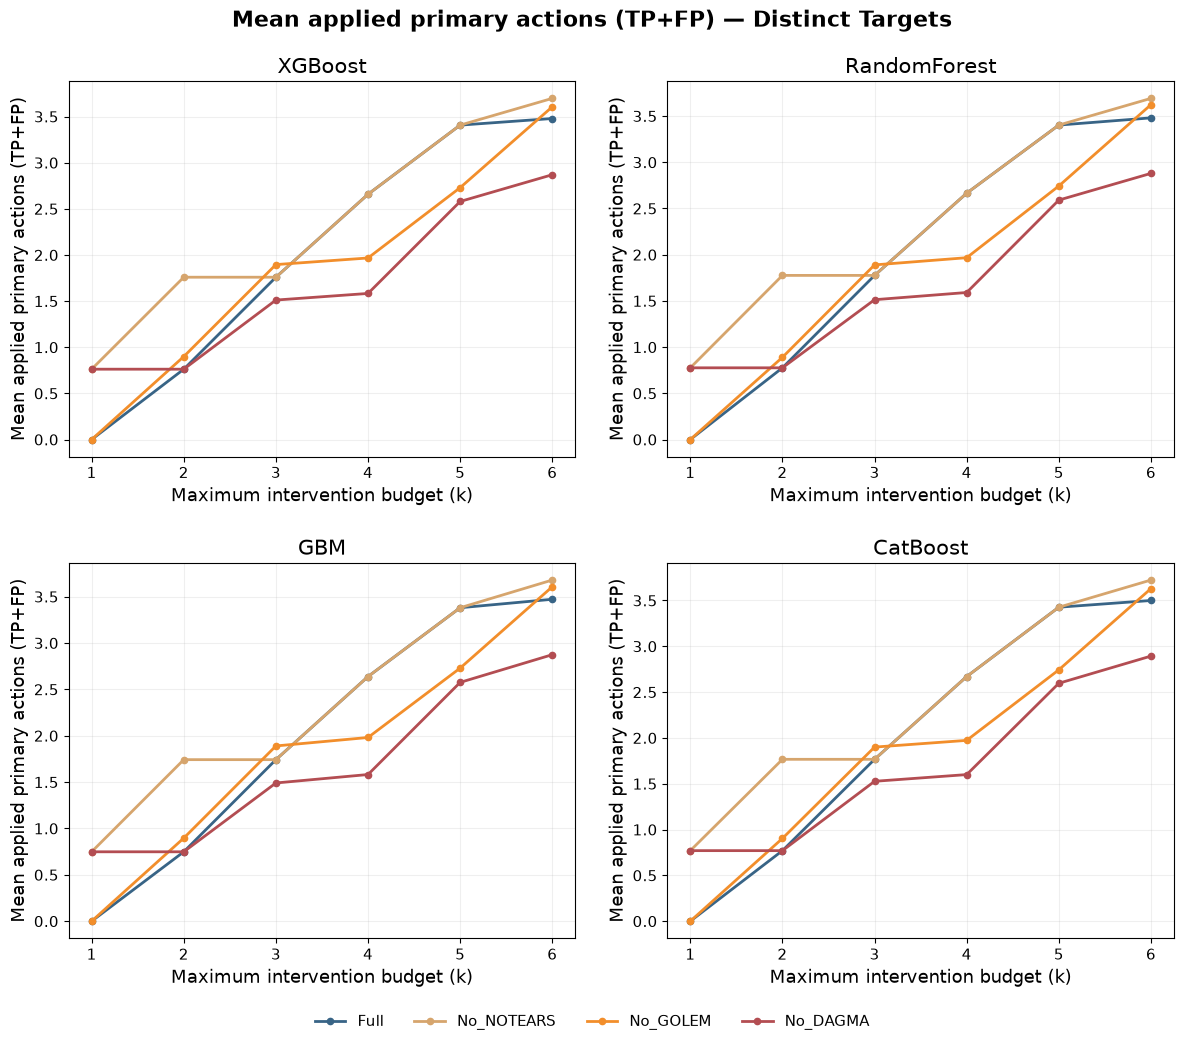

Saved Ablation_DistinctTargets_Applied_Actions_600dpi.png


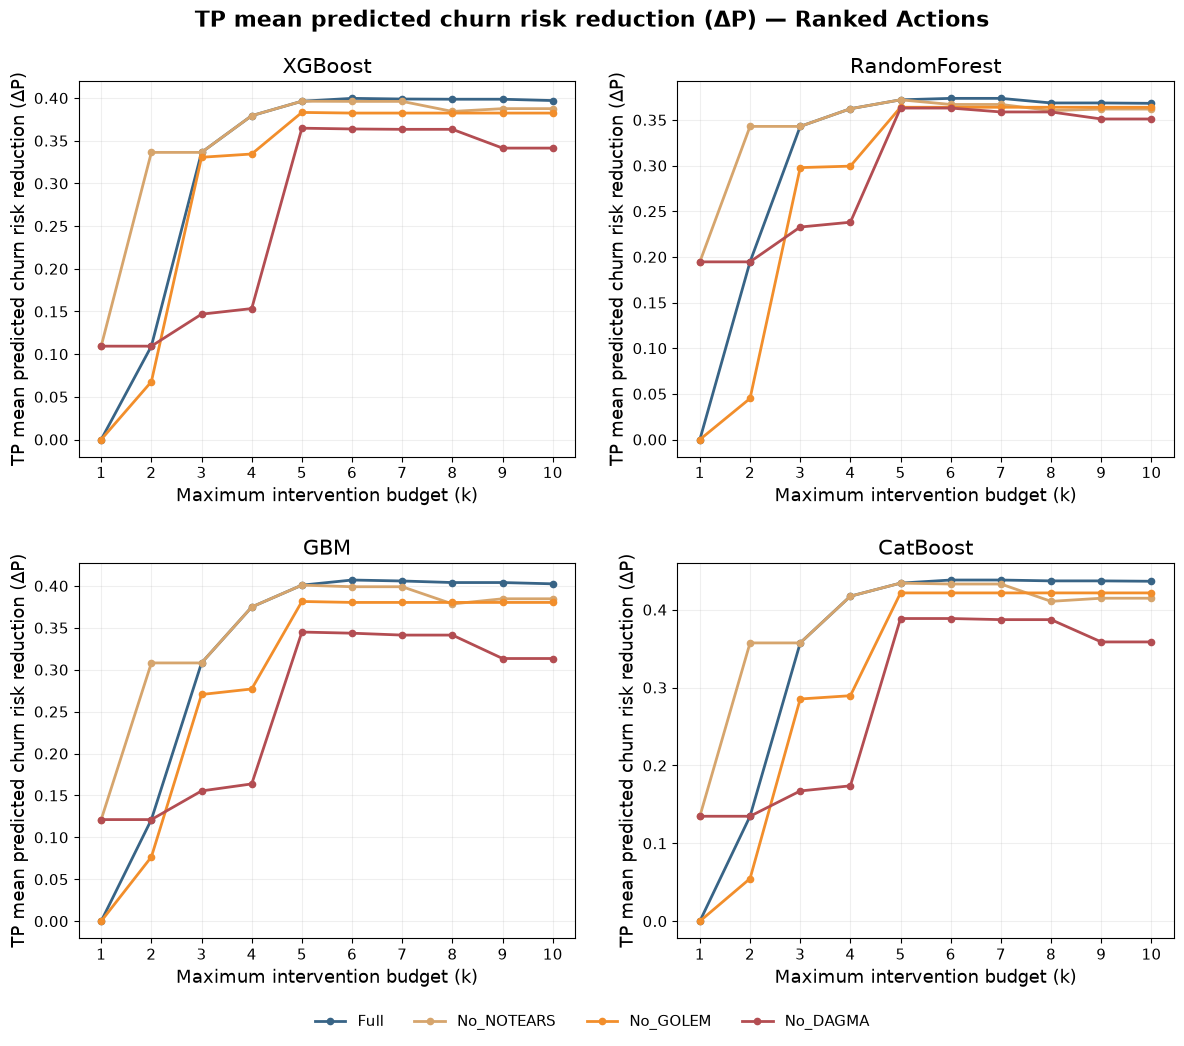

Saved Ablation_RankedRows_TP_Mean_Delta_P_600dpi.png


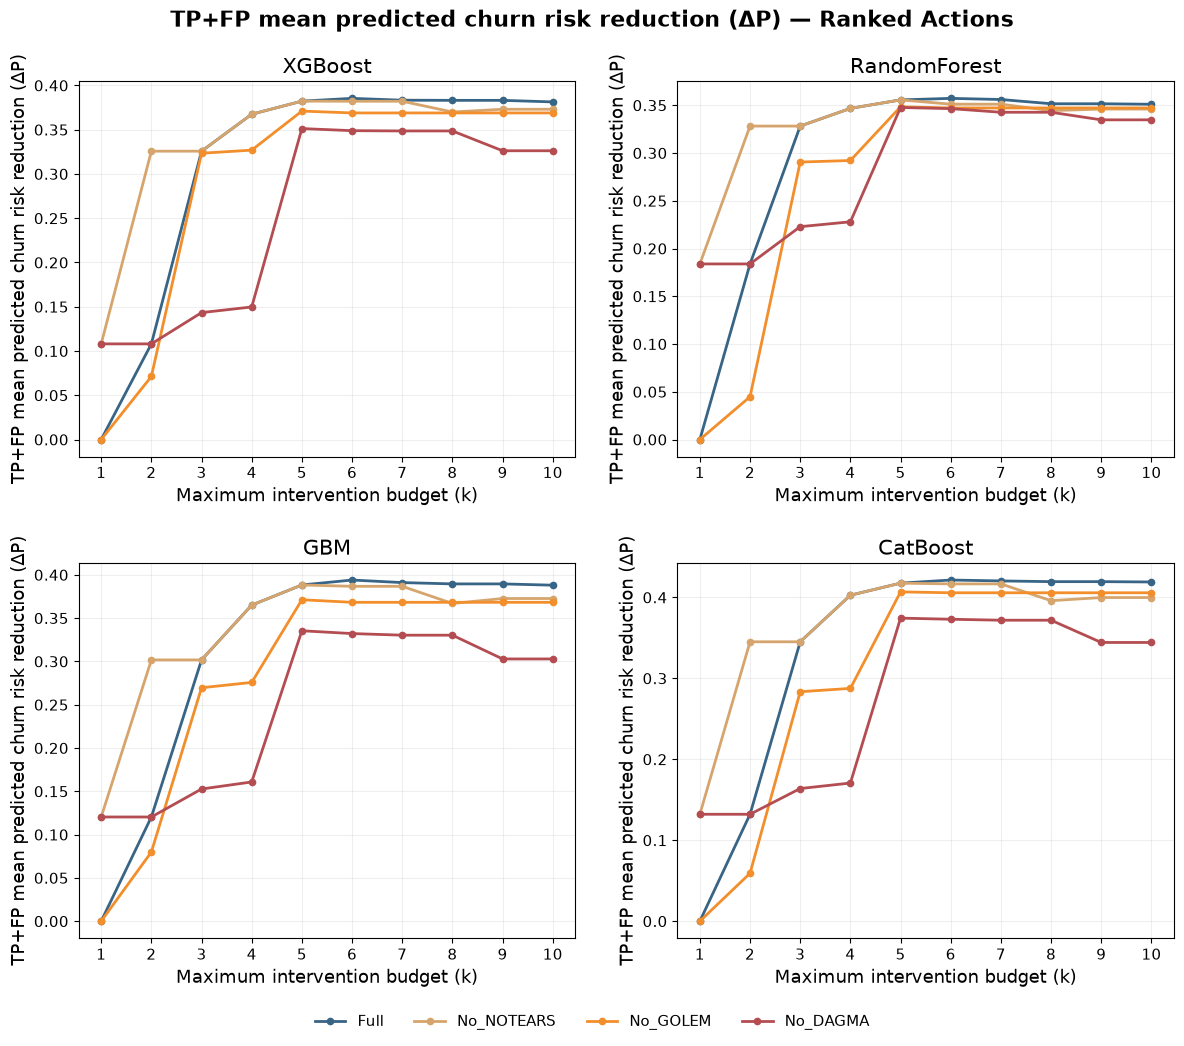

Saved Ablation_RankedRows_Targeted_Mean_Delta_P_600dpi.png


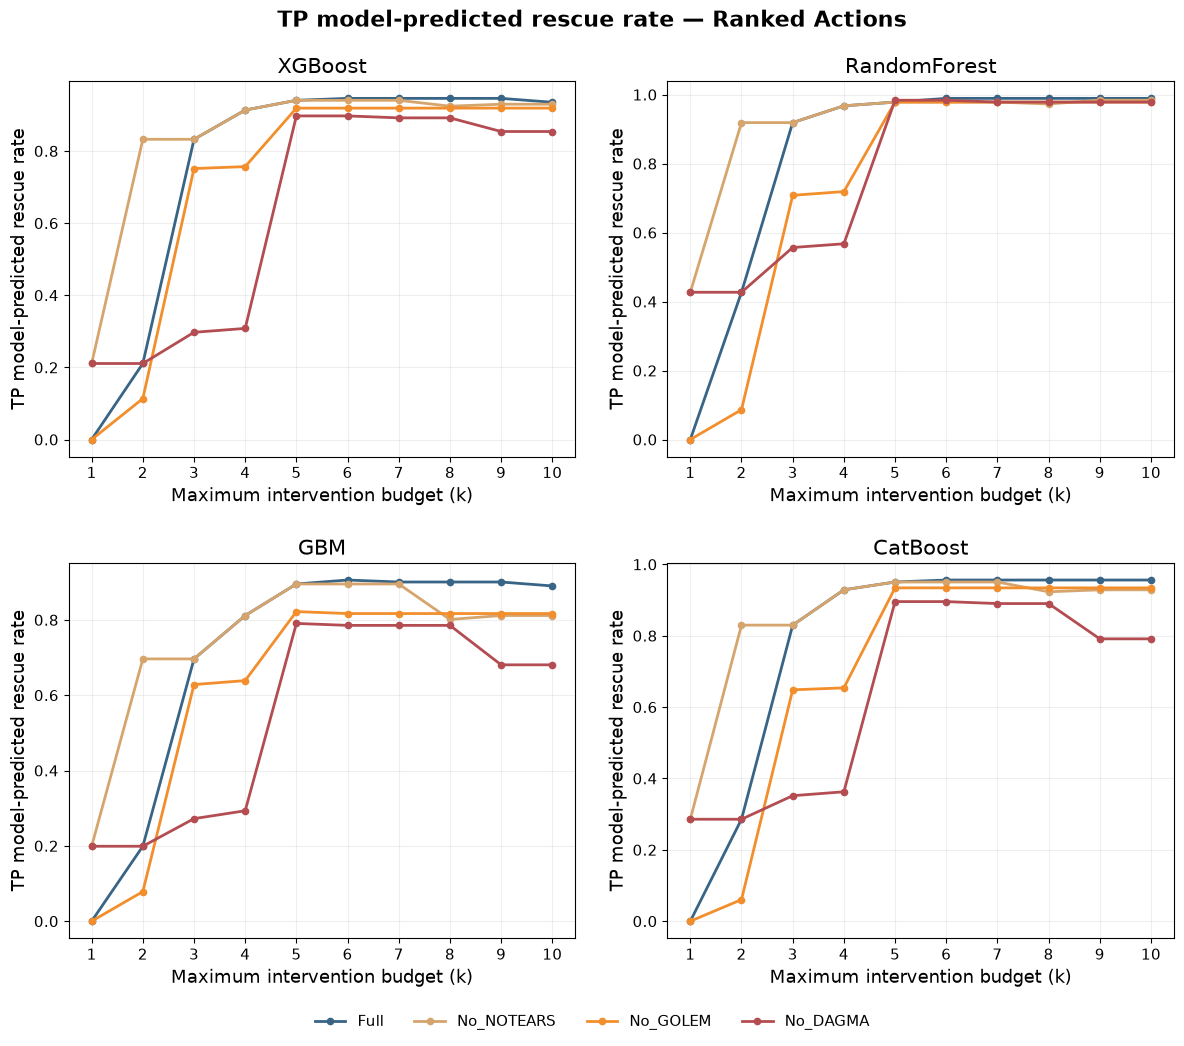

Saved Ablation_RankedRows_TP_Rescue_Rate_600dpi.png


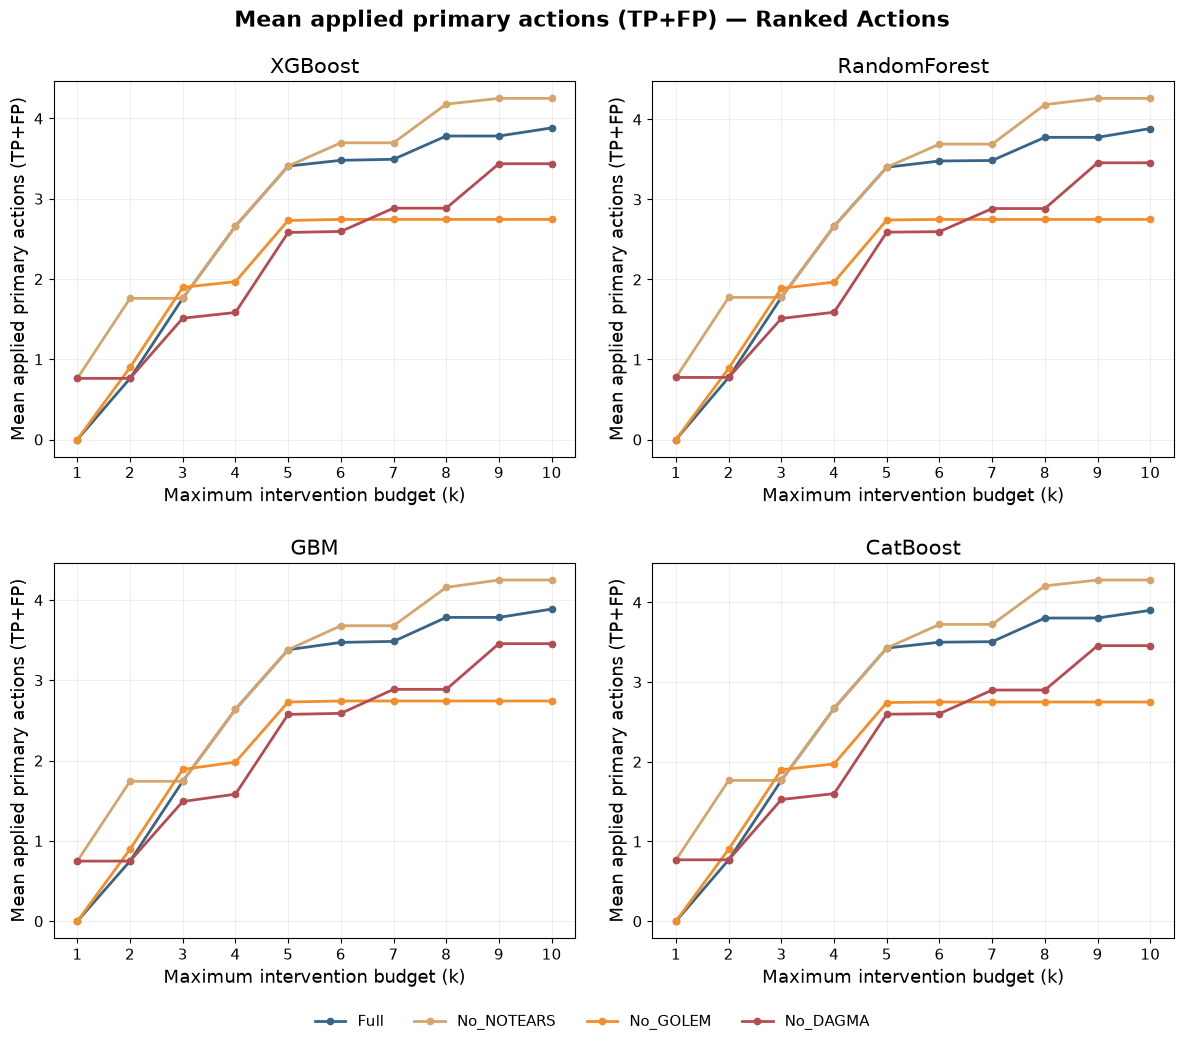

Saved Ablation_RankedRows_Applied_Actions_600dpi.png


In [10]:
COLORS={"Full":"#386486","No_NOTEARS":"#D6A56D","No_GOLEM":"#F28E2B","No_DAGMA":"#B34D52"}
plt.rcParams.update({"font.size":12,"axes.titlesize":15,"axes.labelsize":13,"xtick.labelsize":11,"ytick.labelsize":11,"legend.fontsize":11})
for budget_type in ["DistinctTargets","RankedRows"]:
    for metric,cohort,filename,ylabel in [
        ("Mean_Delta_P","TP","TP_Mean_Delta_P","TP mean predicted churn risk reduction (ΔP)"),
        ("Mean_Delta_P","TP+FP","Targeted_Mean_Delta_P","TP+FP mean predicted churn risk reduction (ΔP)"),
        ("Threshold_Crossing_Rate","TP","TP_Rescue_Rate","TP model-predicted rescue rate"),
        ("Mean_Applied_Primary_Actions","TP+FP","Applied_Actions","Mean applied primary actions (TP+FP)")]:
        fig,axes=plt.subplots(2,2,figsize=(12,11),sharex=True)
        for ax,m in zip(axes.flat,expected_models):
            sub=cohort_df[(cohort_df.Budget_Type==budget_type)&(cohort_df.Model==m)&(cohort_df.Cohort==cohort)]
            for cfg in CONFIGS:
                q=sub[sub.Configuration==cfg].sort_values("k")
                ax.plot(q.k,q[metric],marker="o",linewidth=2.0,markersize=4.5,color=COLORS[cfg],label=cfg)
            ax.set_title(m,pad=6)
            ax.grid(alpha=.2)
            ax.set_xticks(range(1, int(sub.k.max()) + 1))
            ax.tick_params(axis="x", which="both", labelbottom=True)  # show k on every subplot, including top row
            ax.set_xlabel("Maximum intervention budget (k)")
            ax.set_ylabel(ylabel)
        handles,labels=axes.flat[0].get_legend_handles_labels()
        fig.legend(handles,labels,loc="lower center",bbox_to_anchor=(.5,0.02),ncol=4,frameon=False)
        display_budget_type = {"RankedRows": "Ranked Actions", "DistinctTargets": "Distinct Targets"}.get(budget_type, budget_type)
        fig.suptitle(f"{ylabel} — {display_budget_type}",fontsize=16,fontweight="bold",y=0.96)
        fig.tight_layout(rect=[0,.055,1,.97],h_pad=2,w_pad=2)
        path=FIGURE_DIR/f"Ablation_{budget_type}_{filename}_600dpi.png"
        fig.savefig(path,dpi=600,bbox_inches="tight")
        plt.show();plt.close(fig)
        print("Saved",path.name)


## 8. Export all results

In [ ]:
with pd.ExcelWriter(OUTPUT_FILE,engine="openpyxl") as writer:
    availability_df.to_excel(writer,sheet_name="Action Availability",index=False)
    overlap_df.to_excel(writer,sheet_name="Feature Overlap",index=False)
    baseline_df.to_excel(writer,sheet_name="Frozen Baseline",index=False)
    selected_df.to_excel(writer,sheet_name="Selected Actions",index=False)
    cohort_df.to_excel(writer,sheet_name="Budget Cohort Summary",index=False)
    paired_df.to_excel(writer,sheet_name="Paired Bootstrap CI",index=False)
    customer_df.to_excel(writer,sheet_name="Customer Level",index=False)
    action_log_df.to_excel(writer,sheet_name="Action Application Log",index=False)
print("Saved",OUTPUT_FILE)


## Interpretation

- The primary distinct-target analysis avoids counting multiple source features that prescribe a change to the same target as independent interventions. It retains the highest-ranked source recommendation for each target.
- Fixed maximum budgets do not imply equal actual numbers of actions applied. `Mean_Applied_Primary_Actions` and `Pct_With_Any_Applied_Action` can be compared alongside ΔP.
- Feature overlap uses recommended-action `Source` values. Spearman's ρ uses only shared sources; it may be undefined for fewer than two shared features or constant ranks. Source overlap is not the same as overlap of recommended-action target attributes.
- The same frozen baseline TP/FP customers are used for all strategies within each model. The paired bootstrap evaluates differences in model-predicted probability changes, not realized causal retention effects.
- Candidate interventions and the 10% `MonthlyCharges` reduction follow the existing Intervention_Simulation notebook conventions. 